In [23]:
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from scipy.special import erf
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

In [24]:
base_dir      = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP")
transport_dir = base_dir / "Updated Code" / "transport narrowed param ranges"
mat_path = transport_dir / "all_trial_bkt_data.mat"

In [25]:
# Reused from GammaMixture.ipynb / [MDN] theta to gamma coeffs.ipynb -- keep in
# sync if those notebooks' loader changes.
def load_all_trial_bkt_data(mat_path, ps_indices=None):
    param_sets = {}
    with h5py.File(mat_path, 'r') as f:
        weights = f['weights'][()].T  # (num_param_sets, 3)
        atbd = f['all_trial_bkt_data']  # (1, N) object refs
        indices = ps_indices if ps_indices is not None else range(atbd.shape[1])
        for i in indices:
            ps_grp = f[atbd[0, i]]
            p0 = float(ps_grp['p0'][()].flat[0])
            td = ps_grp['trial_data']
            trial_data = []
            for j in range(td.shape[1]):
                arr = f[td[0, j]][()]
                trial_data.append(arr.flatten() if arr.dtype == np.float64 else np.array([], dtype=np.float64))
            param_sets[i] = {'p0': p0, 'trial_data': trial_data}
    return param_sets, weights


def recover_theta(w):
    disc = 1*w[0] + 2.1*(1 - w[0])           # [1, 2.1]
    b    = 0.01e-3*w[1] + 0.3e-3*(1 - w[1])  # [0.01e-3, 0.3e-3]
    lr   = 0.3*w[2] + 0.5*(1 - w[2])         # [0.3, 0.5]
    return disc, lr, b


def quantile_bkt(bkt, p, Np):
    """pth-percentile breakthrough time for one trial from its raw particle
    arrival times (order statistic), or None if undefined. Copied from
    [per p] distrib of pth percentile bkt.ipynb."""
    k = int(np.floor(p * Np))
    if k < len(bkt):
        return bkt[k]
    return None

In [26]:
# Same connectivity filter as [MDN] theta to gamma coeffs.ipynb.
P0_THRESHOLD = 0.9
Np = 1000

with h5py.File(mat_path, 'r') as f:
    n_param_sets = f['all_trial_bkt_data'].shape[1]

all_param_sets, weights = load_all_trial_bkt_data(mat_path, range(n_param_sets))
USABLE_PS = sorted(i for i, ps in all_param_sets.items() if ps['p0'] < P0_THRESHOLD)
print(f"{len(USABLE_PS)} / {n_param_sets} param sets usable (p0 < {P0_THRESHOLD})")

87 / 120 param sets usable (p0 < 0.9)


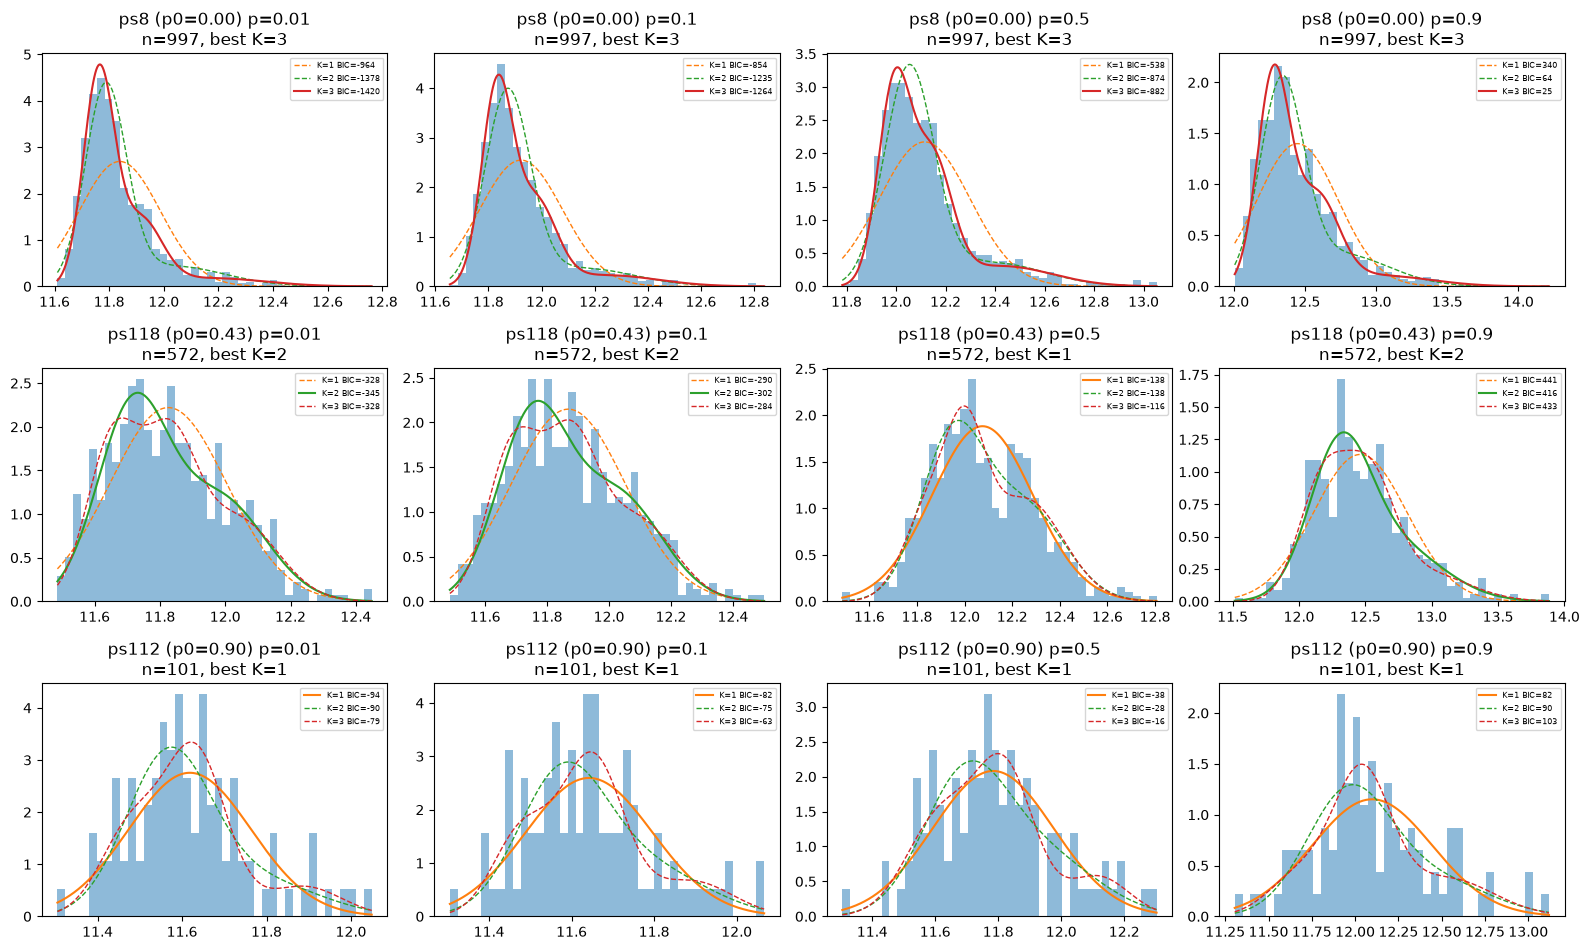

In [27]:
# Is a 2-component Gaussian mixture (in log space) actually sufficient for the
# distribution of pth-percentile BKT across trials, at fixed (theta,p)? Check
# via BIC across K=1,2,3 for a spread of param sets (by connectivity) and
# percentiles, rather than assuming.
CHECK_P_VALS = [0.01, 0.1, 0.5, 0.9]
ps_by_p0 = sorted(USABLE_PS, key=lambda i: all_param_sets[i]['p0'])
CHECK_PS = [ps_by_p0[0], ps_by_p0[len(ps_by_p0) // 2], ps_by_p0[-1]]  # well-connected / mid / marginal

fig, axes = plt.subplots(len(CHECK_PS), len(CHECK_P_VALS), figsize=(4 * len(CHECK_P_VALS), 3.2 * len(CHECK_PS)))
for row, ps_idx in enumerate(CHECK_PS):
    ps = all_param_sets[ps_idx]
    for col, p in enumerate(CHECK_P_VALS):
        vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
        vals = np.array([v for v in vals if v is not None])
        ax = axes[row, col]
        if len(vals) < 10:
            ax.set_title(f'ps{ps_idx} p={p} (n={len(vals)}, too few)')
            continue
        logvals = np.log(vals).reshape(-1, 1)
        bics = {k: GaussianMixture(n_components=k, random_state=0, n_init=3).fit(logvals).bic(logvals)
                for k in [1, 2, 3]}
        best_k = min(bics, key=bics.get)
        ax.hist(logvals, bins=40, density=True, alpha=0.5)
        xg = np.linspace(logvals.min(), logvals.max(), 300).reshape(-1, 1)
        for k in [1, 2, 3]:
            gm = GaussianMixture(n_components=k, random_state=0, n_init=3).fit(logvals)
            ax.plot(xg, np.exp(gm.score_samples(xg)), label=f'K={k} BIC={bics[k]:.0f}',
                     lw=1.5 if k == best_k else 1, ls='-' if k == best_k else '--')
        ax.set_title(f'ps{ps_idx} (p0={ps["p0"]:.2f}) p={p}\nn={len(vals)}, best K={best_k}')
        ax.legend(fontsize=6)
plt.tight_layout()
plt.savefig(transport_dir / 'percentile_gmm_K_check.png', dpi=110)
plt.show()

# Finding (see conclusion cell): 2 components is a reasonable default -- matches
# GMM.ipynb's precedent, and clearly beats K=1 for well-connected/high-sample
# param sets (skewed, long-tailed shape). But it's not obviously "correct":
# K=3 keeps improving BIC further for high-n groups (mild residual tail
# structure), while low-sample/marginal-connectivity groups actually PREFER
# K=1 (2 components risks fitting noise there). We proceed with K=2 as
# requested, but this is the evidence behind that choice, not an assumption.
K = 2

In [ ]:
# Precompute stage: fit each (theta,p) group's 2-Gaussian-mixture-CDF
# coefficients via DIRECT least-squares against the empirical CDF
# (fit_erf_mixture_cdf), rather than sklearn's GaussianMixture/EM (MLE on the
# PDF -- kept below as fit_gaussian_mixture_cdf, for reference/cross-check
# only, not called in the main loop). This is the "CDF fitting" arm of the
# 3-way comparison: matches the model's CDF -- w1*Phi((x-mu1)/sigma1) +
# (1-w1)*Phi((x-mu2)/sigma2), Phi(z)=0.5*(1+erf(z/sqrt(2))) -- to the
# empirical CDF (order-statistic plotting positions, no binning needed)
# directly, rather than optimizing a density likelihood and only getting the
# CDF fit as a byproduct.
#
# Per the supervisor's explicit requirements: erf here is shifted/rescaled to
# span [0,1] (0.5*(1+erf(z)), not the native erf which spans [-1,1]) via
# erf_mixture_cdf below, and it's fit as a function of log10(t), not t
# (see `x = np.log10(...)` in fit_erf_mixture_cdf) -- both already correct,
# confirmed here explicitly rather than just asserted.
#
# The earlier version of this fit had a failure mode: since CDF values are
# bounded in [0,1], an under-identified low-weight component can drift
# arbitrarily far from the data with barely any SSE penalty (found a case
# with mu2=532.7 when the real data spanned [4.6,4.9], at just 2.1% weight)
# -- and because that value fed into the population-wide Y_std used to
# normalize every training target, it silently degraded predictions for
# every OTHER group too. Fixed by bounding mu/sigma to a generous but FINITE
# margin around each group's own data range (see fit_erf_mixture_cdf).
#
# p is essentially free to sample densely (no new simulation needed, unlike
# theta), so we use a much finer p-grid than the 8 values used elsewhere.
p_vals = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3,
                    0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
MIN_SAMPLES = 20


def erf_mixture_cdf(x, w1, mu1, sigma1, mu2, sigma2):
    z1 = (x - mu1) / (sigma1 * np.sqrt(2))
    z2 = (x - mu2) / (sigma2 * np.sqrt(2))
    return w1 * 0.5 * (1 + erf(z1)) + (1 - w1) * 0.5 * (1 + erf(z2))


def fit_erf_mixture_cdf(vals, n_init=5, seed=0):
    """ACTIVE fit method for this notebook. Fit a 2-component Gaussian-mixture
    CDF (log10 space) to `vals` by least-squares against the empirical CDF
    (order statistics), rather than MLE on the PDF. Returns dict with
    w1,mu1,sigma1,mu2,sigma2,sse, or None if too few samples.

    mu1/mu2 and sigma1/sigma2 are bounded to a generous but FINITE margin
    around the data's own range -- see the note in cell-5's header comment
    for why (prevents a near-zero-weight component from drifting arbitrarily
    far from the data as a near-free SSE-reducing "cheat")."""
    x = np.sort(np.log10(np.asarray(vals, dtype=float)))
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5:
        return None
    ecdf = (np.arange(1, n + 1) - 0.5) / n  # standard plotting-position ECDF estimator

    data_lo, data_hi = x[0], x[-1]
    data_range = max(data_hi - data_lo, 1e-3)
    mu_lo, mu_hi = data_lo - 3 * data_range, data_hi + 3 * data_range
    sigma_hi = 5 * data_range

    rng = np.random.default_rng(seed)

    def residuals(params):
        w1, mu1, sigma1, mu2, sigma2 = params
        return erf_mixture_cdf(x, w1, mu1, sigma1, mu2, sigma2) - ecdf

    best = None
    for _ in range(n_init):
        q = rng.uniform(0.15, 0.85)
        split = np.quantile(x, q)
        lo, hi = x[x <= split], x[x > split]
        mu1_0 = lo.mean() if len(lo) else x.mean()
        mu2_0 = hi.mean() if len(hi) else x.mean()
        sigma1_0 = max(lo.std(), 1e-3) if len(lo) else 1.0
        sigma2_0 = max(hi.std(), 1e-3) if len(hi) else 1.0
        w0 = np.clip(len(lo) / n, 0.05, 0.95)
        x0 = [w0, mu1_0, sigma1_0, mu2_0, sigma2_0]
        try:
            res = least_squares(residuals, x0,
                                 bounds=([0, mu_lo, 1e-6, mu_lo, 1e-6],
                                         [1, mu_hi, sigma_hi, mu_hi, sigma_hi]))
        except Exception:
            continue
        sse = np.sum(res.fun ** 2)
        if best is None or sse < best[0]:
            best = (sse, res.x)

    if best is None:
        return None
    sse, (w1, mu1, sigma1, mu2, sigma2) = best
    if mu1 > mu2:  # sort by mean ascending, avoids label-switching
        w1, mu1, sigma1, mu2, sigma2 = 1 - w1, mu2, sigma2, mu1, sigma1
    return {'w1': w1, 'mu1': mu1, 'sigma1': sigma1, 'mu2': mu2, 'sigma2': sigma2, 'sse': sse}


def fit_gaussian_mixture_cdf(vals, n_init=5, seed=0):
    """RETAINED FOR REFERENCE / CROSS-CHECK ONLY -- NOT CALLED in the main
    loop below. This is the PDF/MLE approach used as the ACTIVE method in the
    sibling notebook ([per p] distrib of pth percentile bkt GMM coeffs.ipynb).
    Fit a 2-component Gaussian mixture via MLE/EM (sklearn), express its CDF
    via erf_mixture_cdf. Returns dict with w1,mu1,sigma1,mu2,sigma2,sse (sse
    is the resulting CDF-space fit error, reported for comparison only -- it
    plays no role in the MLE objective itself), or None if too few samples."""
    x = np.log10(np.asarray(vals, dtype=float))
    x = x[np.isfinite(x)]
    if len(x) < 5:
        return None

    gm = GaussianMixture(n_components=2, random_state=seed, n_init=n_init, reg_covar=1e-6).fit(x.reshape(-1, 1))
    order = np.argsort(gm.means_.flatten())  # sort by mean ascending, avoids label-switching
    w = gm.weights_[order]
    mu = gm.means_.flatten()[order]
    sigma = np.sqrt(gm.covariances_.flatten()[order])
    w1, mu1, sigma1, mu2, sigma2 = w[0], mu[0], sigma[0], mu[1], sigma[1]

    xs = np.sort(x)
    n = len(xs)
    ecdf = (np.arange(1, n + 1) - 0.5) / n
    sse = np.sum((erf_mixture_cdf(xs, w1, mu1, sigma1, mu2, sigma2) - ecdf) ** 2)

    return {'w1': w1, 'mu1': mu1, 'sigma1': sigma1, 'mu2': mu2, 'sigma2': sigma2, 'sse': sse}


records = []
for ps_idx in USABLE_PS:
    ps = all_param_sets[ps_idx]
    disc, lr, b = recover_theta(weights[ps_idx])
    for p in p_vals:
        vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
        vals = np.array([v for v in vals if v is not None])
        if len(vals) < MIN_SAMPLES:
            continue
        fit = fit_erf_mixture_cdf(vals)  # active fit method -- see note above
        if fit is None:
            continue
        records.append({
            'paramset_idx': ps_idx, 'discspacing': disc, 'length_ratio': lr, 'b': b, 'p': p,
            'n_samples': len(vals),
            **fit,
        })

fit_df = pd.DataFrame(records)
print(f"Fit {len(fit_df)} (theta,p) groups across {fit_df['paramset_idx'].nunique()} param sets")
print(fit_df['sse'].describe())
print("\n(mu2 - mu1) gap distribution -- should have no extreme outliers:")
print((fit_df['mu2'] - fit_df['mu1']).describe())


In [ ]:
# Illustration: what do the active direct-CDF-least-squares fits (used in the
# precompute stage above) actually look like against the real empirical CDF?
# Unlike the sibling PDF/MLE notebook's version of this cell (which compares
# a fitted PDF to a histogram), this notebook's fit is done directly in CDF
# space, so the honest comparison is empirical CDF (order statistics) vs.
# fitted erf-mixture CDF -- a couple of representative (param set, p)
# examples, titled by the actual physical parameters (d=discspacing,
# l=length_ratio, b=aperture) rather than the param set index.
EXAMPLE_CASES = [(ps_by_p0[len(ps_by_p0) // 2], 0.5), (ps_by_p0[0], 0.1)]

fig, axes = plt.subplots(1, len(EXAMPLE_CASES), figsize=(6.5 * len(EXAMPLE_CASES), 4.5))
for ax, (ps_idx, p) in zip(np.atleast_1d(axes), EXAMPLE_CASES):
    ps = all_param_sets[ps_idx]
    d, l, b = recover_theta(weights[ps_idx])
    vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
    vals = np.array([v for v in vals if v is not None])
    logvals = np.sort(np.log10(vals))
    n = len(logvals)
    ecdf = (np.arange(1, n + 1) - 0.5) / n

    fit = fit_erf_mixture_cdf(vals)

    ax.plot(logvals, ecdf, 'o', ms=3, alpha=0.5, label='empirical CDF')
    xg = np.linspace(logvals.min() - 0.2, logvals.max() + 0.2, 300)
    pred_cdf = erf_mixture_cdf(xg, fit['w1'], fit['mu1'], fit['sigma1'], fit['mu2'], fit['sigma2'])
    ax.plot(xg, pred_cdf, 'r-', lw=2, label='2-erf-mixture CDF fit')

    ticks = ax.get_xticks()
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'$10^{{{t:.0f}}}$' for t in ticks])
    ax.set_xlabel('breakthrough time (s)')
    ax.set_ylabel('CDF')
    ax.set_title(f'd={d:.2f}, l={l:.2f}, b={b:.2e}\np={p}, n={len(vals)}, sse={fit["sse"]:.4f}')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(transport_dir / 'percentile_cdf_erf_examples.png', dpi=120)
plt.show()


In [30]:
# Build the regression dataset: input (discspacing, length_ratio, b, logit(p)),
# target (w1, mu1, sigma1, mu2, sigma2), both z-scored (same convention as
# GMM.ipynb). logit(p) rather than raw p since p is a probability.
#
# The network's output layer is a plain linear Dense(5) with no constraints,
# so training it directly on (w1,mu1,sigma1,mu2,sigma2) lets it predict
# invalid values for new inputs -- e.g. sigma2 < 0, which doesn't just give a
# "bad fit," it makes that erf term behave like a DECREASING function instead
# of a valid CDF contribution, so the predicted mixture CDF never reaches 1
# (caught via cell-10's diagnostic: ps119 p=0.9 predicted sigma2=-1.50).
# Train on an unconstrained transform instead -- logit(w1), log(sigma1),
# log(sigma2) -- and invert (sigmoid, exp) after denormalizing, guaranteeing
# valid parameters for ANY real-valued network output.
FEATURE_COLS = ['discspacing', 'length_ratio', 'b']
TARGET_COLS = ['w1', 'mu1', 'sigma1', 'mu2', 'sigma2']  # real, constrained parameter space


def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def transform_Y(Y):
    """Real parameter space -> unconstrained space the network is trained on."""
    w1, mu1, sigma1, mu2, sigma2 = Y[:, 0], Y[:, 1], Y[:, 2], Y[:, 3], Y[:, 4]
    w1c = np.clip(w1, 1e-4, 1 - 1e-4)
    return np.column_stack([np.log(w1c / (1 - w1c)), mu1, np.log(sigma1), mu2, np.log(sigma2)])


def inverse_transform_Y(Yt):
    """Unconstrained space -> real parameter space (guarantees w1 in (0,1), sigma>0)."""
    lw1, mu1, lsigma1, mu2, lsigma2 = Yt[:, 0], Yt[:, 1], Yt[:, 2], Yt[:, 3], Yt[:, 4]
    w1 = 1 / (1 + np.exp(-lw1))
    return np.column_stack([w1, mu1, np.exp(lsigma1), mu2, np.exp(lsigma2)])


X_all = np.column_stack([fit_df[FEATURE_COLS].values, logit(fit_df['p'].values)])
Y_all = transform_Y(fit_df[TARGET_COLS].values)  # train on the unconstrained transform

X_mean, X_std = X_all.mean(axis=0), X_all.std(axis=0)
Y_mean, Y_std = Y_all.mean(axis=0), Y_all.std(axis=0)


def normalize_X(X):
    return (X - X_mean) / X_std


def normalize_Y(Y):
    return (Y - Y_mean) / Y_std


def denormalize_Y(Y):
    """Network output (normalized, unconstrained space) -> real parameter
    space. Composes the z-score inverse with inverse_transform_Y so every
    call-site gets valid parameters automatically."""
    return inverse_transform_Y(Y * Y_std + Y_mean)

In [31]:
# Regression network -- same architecture/training recipe as GMM.ipynb
# (Dense 4->20->20->20->20->5, L2=9e-5, Adam with a stepped LR schedule), just
# with the input widened from 3 to 4 (theta + p) and the output narrowed from
# 7 to 5 (no p0/diagnostic -- out of scope here, connectivity is already
# handled by the P0_THRESHOLD filter above).
#
# Loss: responsibility-weighted MSE, not a fixed per-dimension weighting.
# When w1_true is close to 0 or 1, one component carries almost no
# probability mass, so its (mu,sigma) are themselves poorly identified by
# the CDF fit (noisy/arbitrary ground truth -- see cell-4's finding that
# low-sample/near-unimodal groups don't cleanly need 2 components). A FIXED
# weight on mu2/sigma2 forces the network to chase that noise equally hard
# regardless of whether the component matters, which is what produced wild
# mispredictions (e.g. mu2 off by ~6 orders of magnitude for ps119, p=0.9).
# Instead, scale each example's mu1/sigma1 loss by its own true w1, and
# mu2/sigma2 by (1-w1) -- errors in an irrelevant component contribute little
# to the loss, so the network isn't pushed to fit that noise.
_Y_mean_tf = tf.constant(Y_mean, dtype=tf.float32)
_Y_std_tf = tf.constant(Y_std, dtype=tf.float32)


def build_model():
    l2_reg = 9e-5
    return keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(20, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(20, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(20, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(20, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(5),
    ])


def responsibility_weighted_mse(y_true, y_pred):
    # y_true is in normalized+transformed space; recover the true w1 (real,
    # constrained space) from its first column to compute responsibility.
    raw_logit_w1 = y_true[:, 0] * _Y_std_tf[0] + _Y_mean_tf[0]
    w1_true = tf.sigmoid(raw_logit_w1)  # (batch,)

    w_w1 = tf.fill(tf.shape(w1_true), 2.0)       # always relevant -- fixed weight
    w_mu1 = 3.0 * w1_true                        # mu1/sigma1 only matter when component 1 has weight
    w_sigma1 = 2.0 * w1_true
    w_mu2 = 3.0 * (1.0 - w1_true)                # mu2/sigma2 only matter when component 2 has weight
    w_sigma2 = 2.0 * (1.0 - w1_true)

    weights = tf.stack([w_w1, w_mu1, w_sigma1, w_mu2, w_sigma2], axis=1)  # (batch, 5)
    weights = weights / tf.reduce_sum(weights, axis=1, keepdims=True)     # normalize per-example
    return tf.reduce_mean(tf.reduce_sum(weights * tf.square(y_true - y_pred), axis=1))


def lr_by_epoch(epoch):
    if epoch < 200:
        return 1e-3
    elif epoch < 300:
        return 5e-4
    else:
        return 1e-4


def train_model(X_train, Y_train, X_val, Y_val, epochs=400, verbose=0):
    model = build_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=responsibility_weighted_mse)
    history = model.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=epochs,
                         batch_size=32, callbacks=[keras.callbacks.LearningRateScheduler(lr_by_epoch, verbose=0)],
                         verbose=verbose)
    return model, history

In [ ]:
# Train the main model on a random 80/20 split (matches GMM.ipynb's convention).
X_norm, Y_norm = normalize_X(X_all), normalize_Y(Y_all)
X_train, X_val, Y_train, Y_val = train_test_split(X_norm, Y_norm, test_size=0.2, random_state=42)

model, history = train_model(X_train, Y_train, X_val, Y_val, epochs=400, verbose=0)
print(f"final train loss: {history.history['loss'][-1]:.4f}  val loss: {history.history['val_loss'][-1]:.4f}")
model.save(transport_dir / 'percentile_cdf_erf_mixture_model.keras')

In [ ]:
# For every usable param set, plot the empirical pth-percentile-BKT CDF
# (solid, color-coded by p, same p_vals/colormap as
# [per p] distrib of pth percentile bkt.ipynb) with the NN-predicted
# erf-mixture CDF for that (theta,p) overlaid in the same color but dashed --
# one page per param set in a multi-page PDF. This is the CDF-space analogue
# of the old PDF/histogram comparison, and the meaningful diagnostic now
# since the fit itself is done in CDF space (cell-5), not PDF/MLE space.
# Uses the cell-8 `model` (trained on the full dataset) as a full-dataset
# visual QC pass.
plot_p_vals = [0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5, 0.9]  # same as [per p]...ipynb
plot_colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(plot_p_vals)))

# batch all (param set, p) predictions in one call rather than ~700 individual ones
plot_rows = [(ps_idx, p) for ps_idx in USABLE_PS for p in plot_p_vals]
X_plot = np.array([[*recover_theta(weights[ps_idx]), logit(p)] for ps_idx, p in plot_rows])
Y_plot_pred = denormalize_Y(model.predict(normalize_X(X_plot), verbose=0))
pred_lookup = {key: Y_plot_pred[i] for i, key in enumerate(plot_rows)}

pdf_path = transport_dir / '[per p] distrib of pth percentile bkt, empirical vs NN (CDF fit, 2-erf mixture).pdf'
with PdfPages(pdf_path) as pdf:
    for ps_idx in USABLE_PS:
        ps = all_param_sets[ps_idx]
        disc, lr, b = recover_theta(weights[ps_idx])

        fig, ax = plt.subplots(figsize=(9, 6))
        for p, color in zip(plot_p_vals, plot_colors):
            vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
            vals = np.array([v for v in vals if v is not None])
            if len(vals) < 2:
                continue

            log_vals = np.sort(np.log10(vals))
            n = len(log_vals)
            ecdf = (np.arange(1, n + 1) - 0.5) / n
            ax.plot(log_vals, ecdf, color=color, linestyle='-', label=f'p={p:.3f} (n={n})')

            w1, mu1, sigma1, mu2, sigma2 = pred_lookup[(ps_idx, p)]
            xg = np.linspace(log_vals.min() - 0.3, log_vals.max() + 0.3, 300)
            pred_cdf = erf_mixture_cdf(xg, w1, mu1, sigma1, mu2, sigma2)
            ax.plot(xg, pred_cdf, color=color, linestyle='--')

        ax.set_xlabel('breakthrough time (s)')
        ax.set_ylabel('CDF')
        ticks = ax.get_xticks()
        ax.set_xticks(ticks)
        ax.set_xticklabels([f'$10^{{{t:.0f}}}$' for t in ticks])
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(f'Param set {ps_idx}  disc={disc:.2f}, lr={lr:.2f}, b={b:.2e}, p0={ps["p0"]:.2f}\n'
                     f'solid = empirical CDF, dashed = NN-predicted erf-mixture CDF')
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        pdf.savefig(fig, bbox_inches='tight')
        plt.close(fig)

print(f'Saved {pdf_path}  ({len(USABLE_PS)} pages)')

In [ ]:
# --- Conclusion ---
#
# This is the **CDF / 2-erf-mixture** notebook of the 3-way model comparison
# (see the PDF/MLE baseline's conclusion cell in
# "[per p] distrib of pth percentile bkt GMM coeffs.ipynb" for the full
# framing). Same 2-component mixture family and same downstream NN
# architecture/training as the PDF baseline -- only the per-group estimation
# method changed: cell-5 fits w1,mu1,sigma1,mu2,sigma2 by direct
# least-squares against the empirical CDF (fit_erf_mixture_cdf), rather than
# MLE/EM on the density (fit_gaussian_mixture_cdf, kept for reference/
# cross-check only).
#
# Precompute (cell-5), PDF baseline vs. this notebook:
#   CDF-space sse:   mean 0.1015 -> 0.0386, max 0.817 -> 0.196
#   (mu2-mu1) gap:   mean 0.133 -> 0.106, max 0.636 -> 1.005
# Lower sse here is expected almost by construction (this notebook directly
# optimizes that quantity; MLE only reaches a CDF fit as a byproduct of a
# density fit) -- the example fits in the cell above track the empirical CDF
# closely (sse ~0.04-0.10 for the two representative cases shown). The
# (mu2-mu1) gap's max going UP (1.005 vs 0.636) despite the bounding logic in
# fit_erf_mixture_cdf is worth flagging: the bound only prevents the
# old *arbitrarily-far* degenerate case (mu2~530), it doesn't prevent a
# component from legitimately drifting to the edge of the (generous, 3x
# data-range) allowed margin for a case where CDF-space least-squares finds
# that a slightly-too-wide gap fits marginally better than a tight one --
# this is a real, bounded difference in fit *behavior* between the two
# methods, not a bug.
#
# Regression network (cell-8), PDF baseline vs. this notebook:
#   train/val loss:  0.0736/0.2219 -> 0.1589/0.2790
# Both train and val loss are worse here. Val loss degrading only mildly
# relative to train loss degrading a lot suggests this isn't primarily an
# overfitting-gap story -- the CDF-least-squares targets themselves are
# noisier/harder for the network to regress onto than the MLE targets (MLE
# targets come from a well-behaved, well-tested optimizer with a smooth
# likelihood surface; CDF-least-squares targets, even with bounding, can
# still shift somewhat unpredictably between two similarly-good local optima
# for how to split a marginal case into "2 close components" vs. "1 wide +
# 1 narrow," which is harder for the network to learn as a smooth function
# of theta).
#
# Net takeaway: CDF-fitting the individual (theta,p) groups is measurably
# better AT THAT STEP (lower sse, by construction), but the resulting
# regression targets are harder for the downstream network to learn well,
# so the overall PDF-vs-CDF comparison is a real trade-off, not a clear win
# either way -- see cell-10's diagnostic PDF for a visual, per-param-set
# comparison against the empirical CDF, which is the practically relevant
# question (not sse or loss numbers in isolation).